# 02 — Churn Labelling and Exploratory Analysis

Turns raw event streams into a labelled player cohort, then explores how
churners and retained players differ.

## The churn definition

There is no subscription in these games, so churn must be inferred. Following
the source paper, two windows are used:

- **Observation Period (OP)** — the first *n* days after a player's **first ever**
  session. Every predictive feature is computed here.
- **Churn Prediction Period (CP)** — the following *m* days. A player is a
  **churner** if they record **zero** sessions in this window.

This is stronger than an arbitrary "inactive for 30 days" rule because both
windows are explicit parameters, so the definition can be varied and the
sensitivity of the conclusions measured (see notebook 07).

In [1]:
import sys, warnings
from pathlib import Path

# Allow `from src import ...` when the notebook is run from notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)
print("project root:", ROOT)

project root: D:\Player Churn\player-churn-ml


In [2]:
from src import config, labeling, features, visualisation

GAME = "game1"   # try "game2" or "game3"
OP, CP = config.OBSERVATION_PERIOD_DAYS, config.CHURN_PREDICTION_PERIOD_DAYS

events = pd.read_parquet(config.INTERIM_DIR / f"{GAME}_events.parquet")
print(f"{GAME}: {len(events):,} events, {events['player_id'].nunique():,} players")
print(f"windows: OP={OP} days, CP={CP} days")

game1: 153,929 events, 25,956 players
windows: OP=5 days, CP=10 days


## Censoring guards

Two filters are applied that the source paper leaves implicit. Both **shrink**
the cohort, and both remove label noise that would otherwise inflate measured
performance:

- **Right guard** — a player's whole OP+CP window must fit inside the observed
  log. Otherwise "no sessions during CP" only means the data ended, not that the
  player left. Without this the model is partly learning *when* the log stops.
- **Left guard** — a player first seen at the very start of the log may have been
  playing before logging began, so they are not genuinely new.

In [3]:
cohort = labeling.build_cohort(events, OP, CP)
cohort.head()

  cohort: 25,956 players -> 25,422 after left guard -> 25,121 after right guard -> 25,121 with OP activity | churn rate 92.6%


,player_id,first_ts,op_end,cp_end,n_events_op,n_events_cp,churn
0,0,1428753158,1429185158,1430049158,3,0,1
1,000000000000000,1421978684,1422410684,1423274684,3,0,1
2,010941525590041,1436265180,1436697180,1437561180,1,0,1
3,012345678901237,1424661883,1425093883,1425957883,2,0,1
4,012345678912345,1424595106,1425027106,1425891106,5,0,1


In [4]:
print(f"players        : {len(cohort):,}")
print(f"churners       : {cohort.churn.sum():,}")
print(f"churn rate     : {cohort.churn.mean():.2%}")
print(f"retained       : {(1 - cohort.churn).sum():,}")
print(f"median events in OP: {cohort.n_events_op.median():.0f}")

players        : 25,121
churners       : 23,261
churn rate     : 92.60%
retained       : 1,860
median events in OP: 2


> **Note the class balance.** These cohorts are heavily churn-dominated. The
> *retained* player is the rare class, which is why later notebooks lead with
> retained-class PR-AUC and balanced accuracy rather than accuracy — predicting
> "everyone churns" already scores above 0.90 accuracy while being useless.

## Feature engineering

All features come from events with `ts < op_end`, so nothing from the label
window can leak in. Families:

| Family | Features |
|--------|----------|
| activity / frequency | `play_count`, `active_days`, `session_count`, `recency_hours`, gap statistics |
| engagement trajectory | `day0_plays`…`day4_plays`, `first_vs_last_day_ratio`, `consecutive_play_ratio` |
| progression / mastery | `score_best/mean/worst/std`, `score_slope`, `score_improvement` |
| difficulty / frustration | `win_ratio`, `fail_ratio`, `quit_ratio`, `max_loss_streak`, `fail_state_diversity` |
| monetisation | `purchase_count`, `purchase_total`, `paid_*`, `first_purchase_day` |
| context (fairness only) | `platform`, `device_family` |

In [5]:
feats = features.prune_features(features.build_features(events, cohort, OP))
model_cols = features.feature_columns(feats)

print(f"feature matrix: {feats.shape[0]:,} players x {len(model_cols)} model features")
feats.head()

  dropped 2 uninformative columns: std_gap_hours, activity_slope
feature matrix: 25,121 players x 29 model features


,player_id,churn,first_ts,play_count,active_days,active_duration_hours,recency_hours,plays_per_active_day,weekend_ratio,night_ratio,hour_spread,mean_gap_hours,max_gap_hours,session_count,mean_session_minutes,max_session_minutes,mean_plays_per_session,total_playtime_minutes,day0_plays,day1_plays,day2_plays,day3_plays,day4_plays,first_vs_last_day_ratio,consecutive_play_ratio,score_best,score_mean,score_worst,score_std,score_median,score_slope,score_improvement,platform
0,0,1,1428753158,3,1,0.031667,119.968333,3.0,1.0,0.0,0.0,0.015833,0.016389,1,1.900000,1.900000,3.0,1.900000,3,0,0,0,0,0.250000,0.0,115.0,58.000000,14.0,51.739733,45.0,-15.5,-66.0,Android
1,000000000000000,1,1421978684,3,1,0.017778,119.982222,3.0,0.0,1.0,0.0,0.008889,0.013333,1,1.066667,1.066667,3.0,1.066667,3,0,0,0,0,0.250000,0.0,7.0,3.333333,1.0,3.214550,2.0,0.5,-2.0,Android
2,010941525590041,1,1436265180,1,1,0.000000,120.000000,1.0,0.0,0.0,NaN,NaN,NaN,1,0.000000,0.000000,1.0,0.000000,1,0,0,0,0,0.500000,0.0,21.0,21.000000,21.0,NaN,21.0,NaN,NaN,Android
3,012345678901237,1,1424661883,2,1,0.014444,119.985556,2.0,0.0,1.0,0.0,0.014444,0.014444,1,0.866667,0.866667,2.0,0.866667,2,0,0,0,0,0.333333,0.0,33.0,32.500000,32.0,0.707107,32.5,-1.0,-1.0,Android
4,012345678912345,1,1424595106,5,1,0.013056,119.986944,5.0,1.0,0.0,0.0,0.003264,0.004722,1,0.783333,0.783333,5.0,0.783333,5,0,0,0,0,0.166667,0.0,30.0,11.200000,0.0,13.479614,3.0,5.6,8.0,Android


## How churners and retained players differ

In [6]:
comparison = (feats.groupby("churn")[model_cols].mean().T
              .rename(columns={0: "retained", 1: "churned"}))
comparison["ratio"] = comparison["retained"] / comparison["churned"].replace(0, np.nan)
comparison.sort_values("ratio", ascending=False).round(3)

churn,retained,churned,ratio
day4_plays,0.913,0.038,23.753
day3_plays,1.166,0.061,19.265
day2_plays,1.656,0.101,16.356
day1_plays,2.376,0.214,11.095
consecutive_play_ratio,0.153,0.018,8.411
active_duration_hours,41.160,6.596,6.241
total_playtime_minutes,16.905,2.848,5.936
play_count,14.811,3.383,4.378
max_session_minutes,9.226,2.352,3.923
max_gap_hours,32.023,10.610,3.018


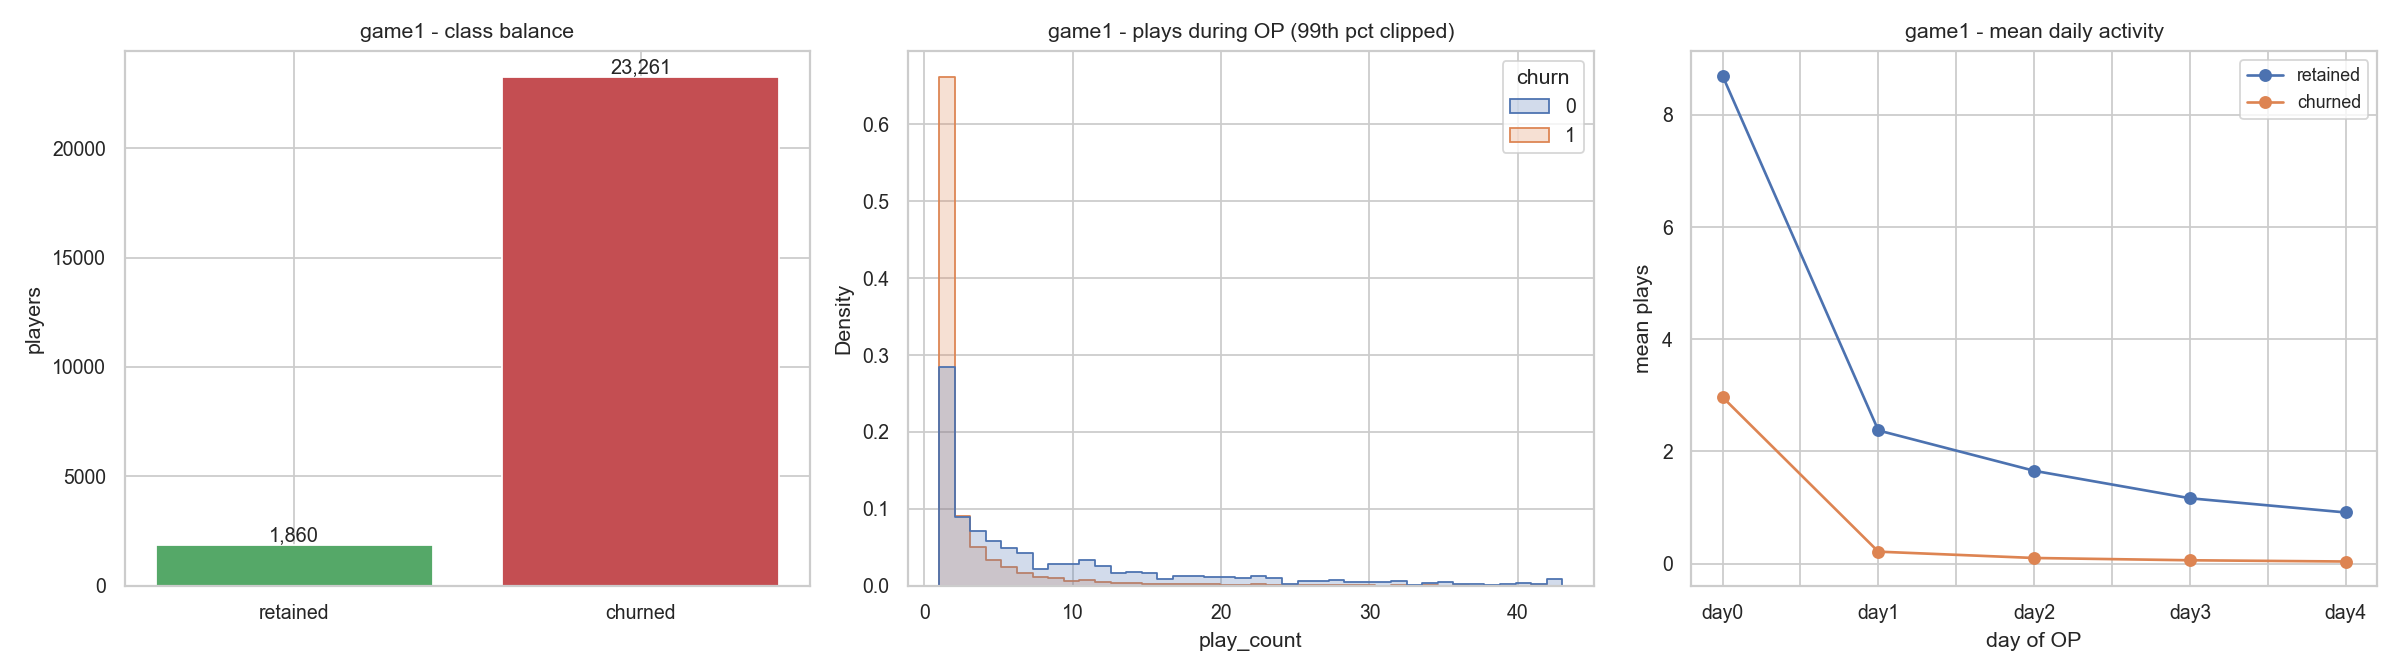

In [7]:
visualisation.plot_cohort_overview(feats, GAME)

from IPython.display import Image
Image(str(config.FIGURE_DIR / f"{GAME}_cohort_overview.png"))

### Activity decay across the observation window

The clearest visual signal: retained players keep playing across the OP, while
churners are concentrated almost entirely in day 0.

In [8]:
day_cols = [c for c in feats.columns if c.startswith("day") and c.endswith("_plays")]

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, grp in feats.groupby("churn"):
    ax.plot(range(len(day_cols)), grp[day_cols].mean().to_numpy(),
            marker="o", lw=2, label="churned" if label else "retained")
ax.set(xlabel="Day of observation period", ylabel="Mean plays",
       title=f"{GAME} — activity trajectory by outcome")
ax.legend()
plt.tight_layout()
plt.show()

### Correlation with churn

A quick univariate view. Strong single features here foreshadow the SHAP
rankings in notebook 04 — but note that correlation cannot show interactions or
non-monotonic effects, which is exactly the gap SHAP fills.

In [9]:
corr = (feats[model_cols + ["churn"]].corr(numeric_only=True)["churn"]
        .drop("churn").sort_values())

fig, ax = plt.subplots(figsize=(8, 9))
colours = ["#55A868" if v < 0 else "#C44E52" for v in corr]
ax.barh(corr.index, corr.to_numpy(), color=colours)
ax.axvline(0, c="k", lw=1)
ax.set(xlabel="Correlation with churn",
       title=f"{GAME} — green protects retention, red predicts churn")
plt.tight_layout()
plt.show()